#Assignment 1

In [ ]:
#Installing Required Packages
!pip install bnlearn scipy seaborn matplotlib pandas numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 29.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.2/185.2 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.6 MB/s eta 0:00:00
  Created wheel for semopy: filename=semopy-2.3.11-py3-none-any.whl size=1659682 sha256=a0ef9dc890d11dd705b9ed11578709beb98f00ee4c9660950b0fe0c047e9cf01
  Stored in directory: /root/.cache/pip/wheels/44/73/aa/17ef39e69a62fdb1cbda5d9ebf8318f130b12107bf05cad7f0
Successfully built semopy


In [ ]:
#Importing libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import bnlearn as bn

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


##Question 1: Exploratory Data Analysis and Variable Selection

##1. Exploratory Data Analysis with a Heatmap

In [ ]:
#Load the dataset
df = pd.read_excel("/content/Subsistence Retail Consumer Data.xlsx")
print("Dataset Shape", df.shape)
df.head()

Dataset Shape (281, 41)


,Gender,Age,Marital Status,Employment Status,Level of Education,Regular Customer,Shopping frequency,E1,E2,E3,...,CT5,CT6,CT7,PV1,PV2,PV3,PI1,PI2,PI3,PI4
0,3,4,1,1,4,2,3,3,2,4,...,3,2,4,2,4,4,3,4,4,4
1,3,5,3,1,4,1,1,3,3,3,...,2,4,3,2,3,2,4,4,4,4
2,2,4,2,2,2,2,2,3,4,2,...,2,4,1,2,3,1,3,3,4,3
3,1,3,1,1,3,2,1,3,2,4,...,2,3,4,1,2,3,3,4,3,4
4,3,2,1,2,2,2,3,2,4,3,...,2,4,2,2,4,2,2,3,2,3


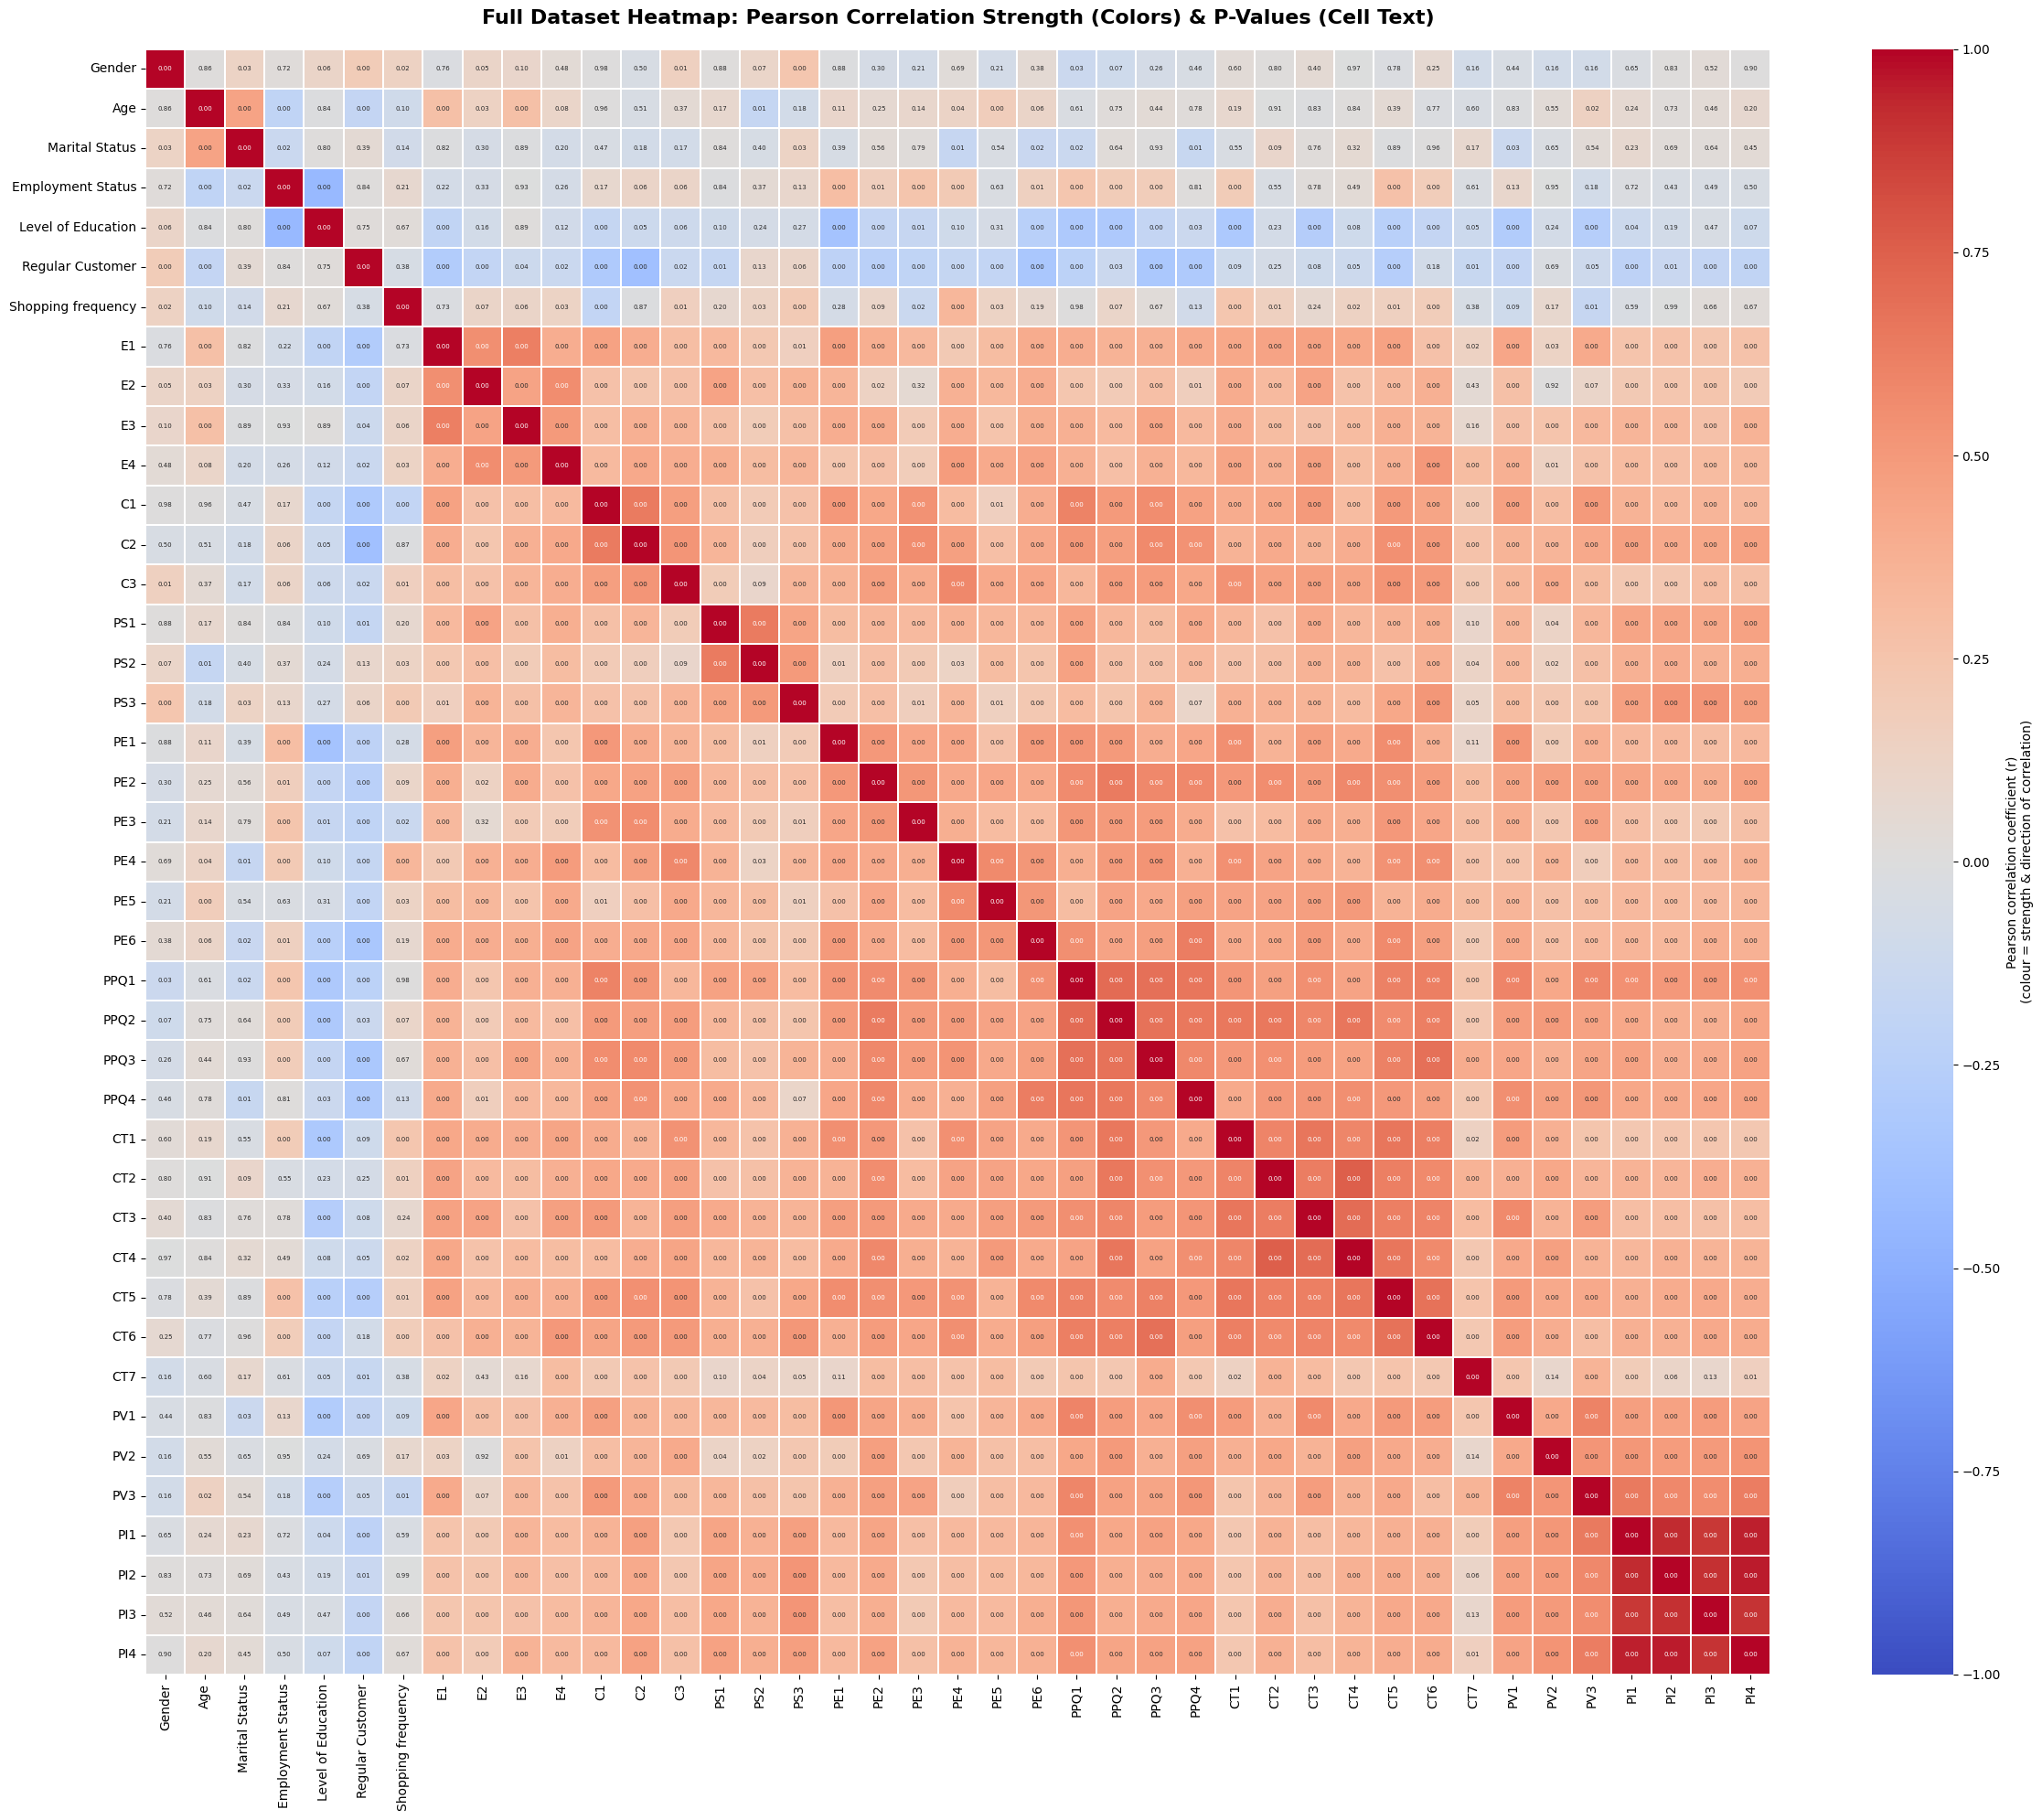

In [ ]:
# Convert all columns to numeric and drop incomplete rows
df_numeric = df.apply(pd.to_numeric, errors='coerce').dropna()

# 2. Calculate Full Pearson Correlation (r) and P-Value Matrices across ALL variables
cols = df_numeric.columns.tolist()
corr_full = pd.DataFrame(index=cols, columns=cols, dtype=float)
p_full = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        r, p = pearsonr(df_numeric[c1], df_numeric[c2])
        corr_full.loc[c1, c2] = r
        p_full.loc[c1, c2] = p

# 3. Plot Heatmap for the whole Dataset
plt.figure(figsize=(24, 20))

# Custom annotation formatting: display P-values rounded to 2 decimal places
annot_pvalues = p_full.astype(float).round(2).astype(str)

sns.heatmap(
    corr_full.astype(float),
    annot=p_full.astype(float),  # Display P-values inside cells
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.3,
    cbar_kws={"label": "Pearson correlation coefficient (r)\n(colour = strength & direction of correlation)"},
    annot_kws={"size": 5}
)

plt.title("Full Dataset Heatmap: Pearson Correlation Strength (Colors) & P-Values (Cell Text)", fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

##2. Understanding the Dataset & Variable Selection

from the 9 distinct categories, one variable category was chosen based on correlation significance:

1. Demographics: Regular Customer
2. Expectations: E3
3. Convenience: C2
4. Product Selection: PS3
5. Physical Environment: PE2
6. Perceived Product Quality: PPQ1
7. Customer Trust: CT5
8. Perceived Value: PV3
9. Purchase Intention: PI1




##3. Justification of Variable Selection
##i. Variable Selection Justification
These variables were selected because the Pearson correlation analysis showed statistically significant association values (p < 0.05) across constructs. Instead of selecting multiple redundant items from the same group, we chose the strongest representative item for each category. There are two main advantages to this strategy:



*    **High Information Capacity**: Each overall construct's statistical strength and vital meaning are captured.
*    **A Sparse and Effective Network**: It avoids two major computational problems during model fitting and inference by keeping the Bayesian Network straightforward:
1. When the model learns random noise from the sample data rather than actual patterns, this is known as overfitting.
2.  When the underlying math tables get too big and complicated for the computer to compute probabilities effectively, this is known as a combinatorial explosion.



  




##ii. Anticipated Insights
Direct vs Indirect Drivers:
It is anticipated that the study will show whether the physical environment (PE2) and convenience (C2) have a direct impact on purchase intention(PI1) or or whether ustomer trust (CT5) and perceived value (PV3) fully mediate their influence.

Demographic Impact: The network will display whether purchasing decisions are made fundamentally differently by different shopper groups. Specifically, it will demonstrate if a person's baseline store expectations (E3) and trust levels are shaped by their customer type (Regular Customer) or whether purchase decisions (PI1) are consistently motivated by a straightforward focus on obtaining good perceived value (PV3).

##Question 2: Creating and Comparing Bayesian Networks

1. Expertly Creating a Direct Acyclic Graph (DAG)

[bnlearn]> Auto generate placeholders for the CPTs.
[bnlearn] >CPT for E3:
+------------------+---------------------+---------------------+
| Regular Customer | Regular Customer(0) | Regular Customer(1) |
+------------------+---------------------+---------------------+
| E3(0)            | 0.5                 | 0.5                 |
+------------------+---------------------+---------------------+
| E3(1)            | 0.5                 | 0.5                 |
+------------------+---------------------+---------------------+
[bnlearn] >CPT for PV3:
+--------+---------+---------+---------+---------+
| C2     | C2(0)   | C2(0)   | C2(1)   | C2(1)   |
+--------+---------+---------+---------+---------+
| PPQ1   | PPQ1(0) | PPQ1(1) | PPQ1(0) | PPQ1(1) |
+--------+---------+---------+---------+---------+
| PV3(0) | 0.5     | 0.5     | 0.5     | 0.5     |
+--------+---------+---------+---------+---------+
| PV3(1) | 0.5     | 0.5     | 0.5     | 0.5     |
+--------+---------+---------+--------

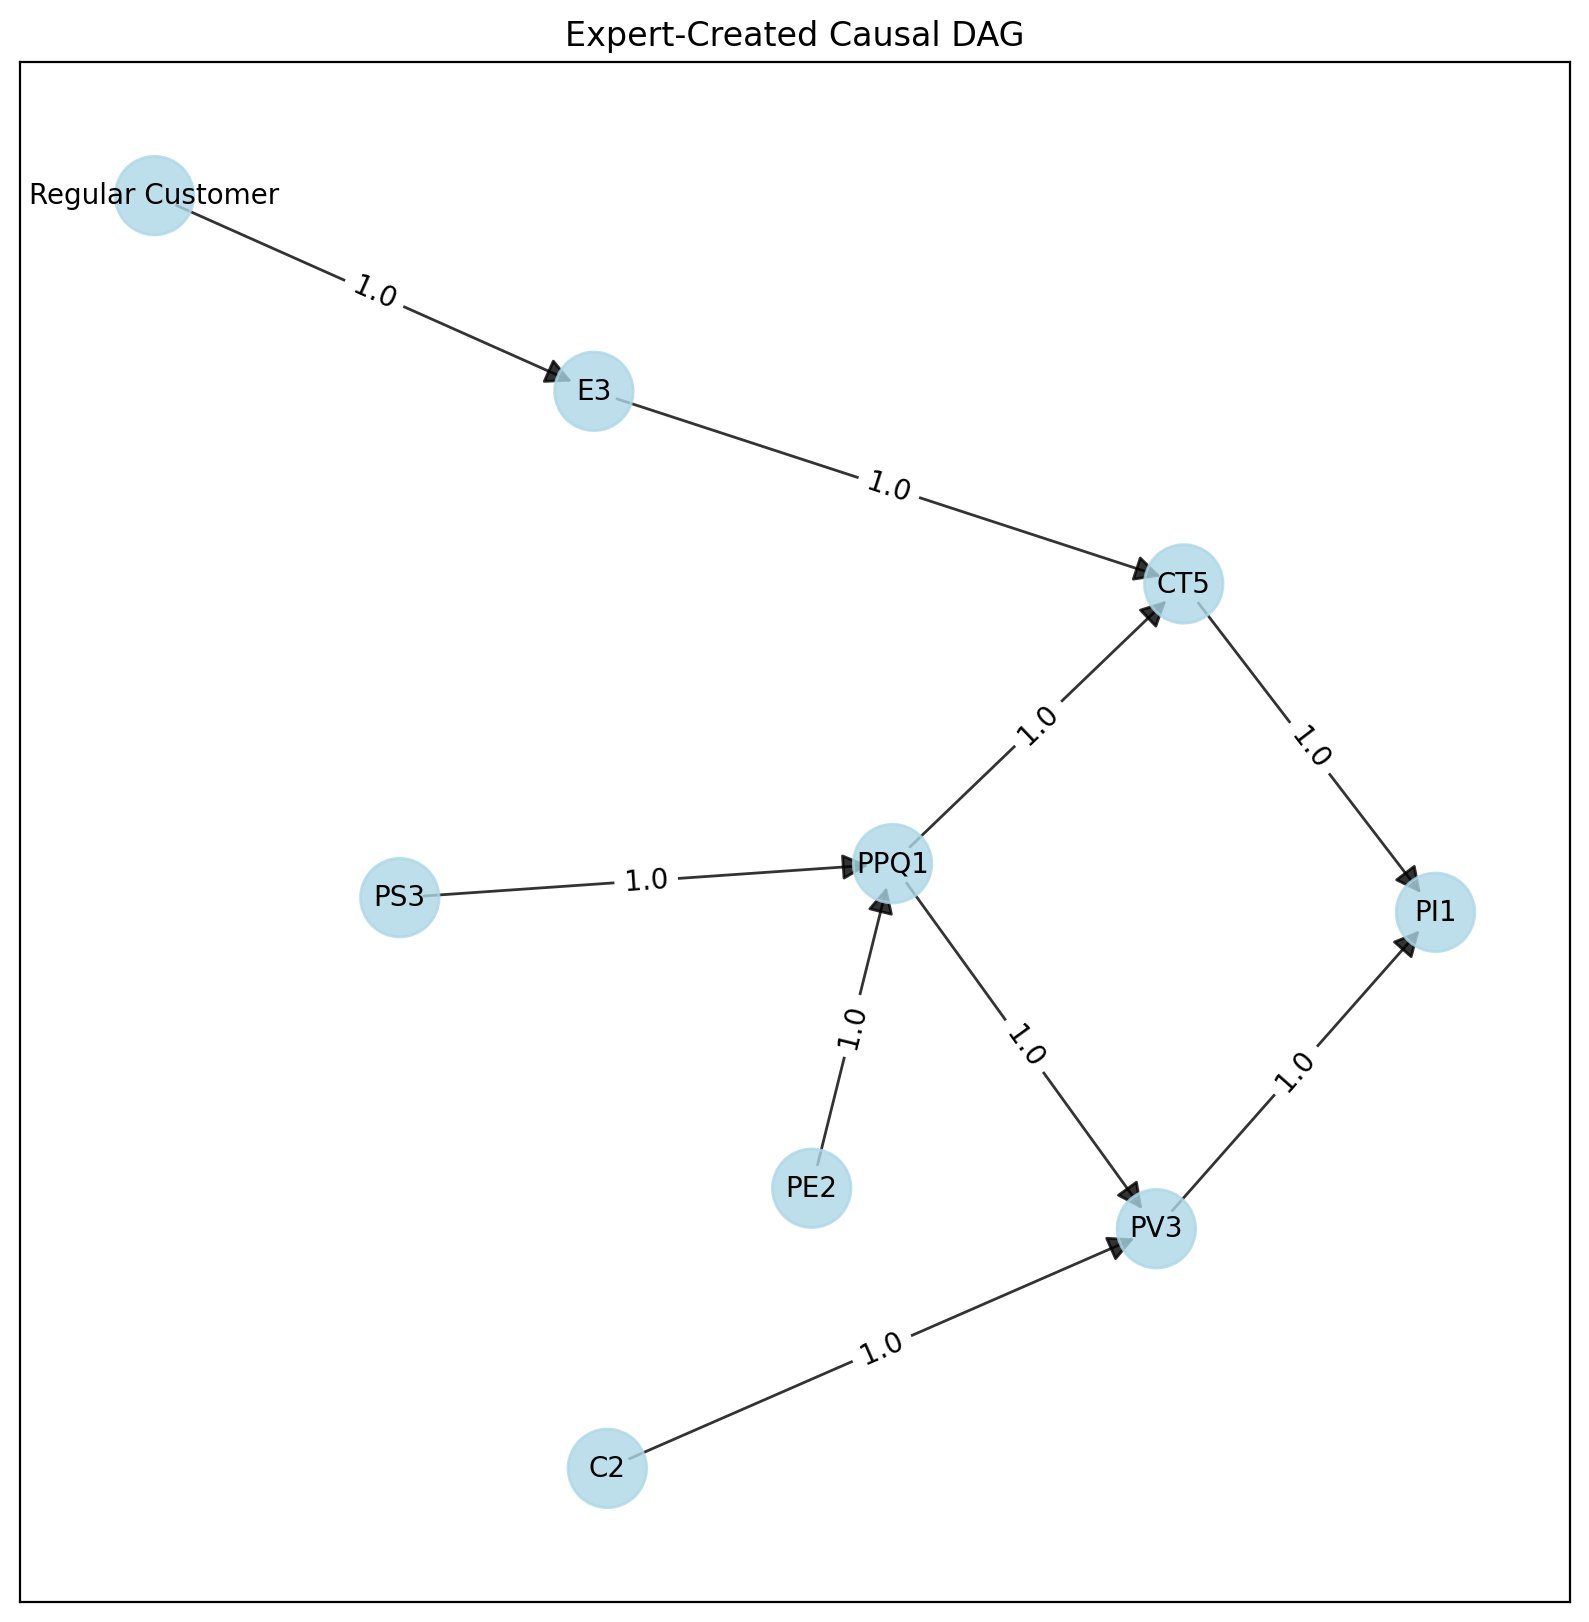

{'fig': <Figure size 2000x2000 with 1 Axes>,
 'ax': <Figure size 2000x2000 with 1 Axes>,
 'pos': {'Regular Customer': array([-1.        ,  0.88447837]),
  'E3': array([-0.32339116,  0.62350784]),
  'C2': array([-0.30274765, -0.81282341]),
  'PV3': array([ 0.54268946, -0.4932497 ]),
  'PS3': array([-0.62231914, -0.05175022]),
  'PPQ1': array([ 0.13645338, -0.00633142]),
  'PE2': array([ 0.01197017, -0.43925495]),
  'CT5': array([0.58485296, 0.36669223]),
  'PI1': array([ 0.97249198, -0.07126873])},
 'G': <networkx.classes.digraph.DiGraph at 0x78ef1f1934d0>,
 'node_properties': {'Regular Customer': {'node_color': '#ADD8E6',
   'node_size': 800},
  'E3': {'node_color': '#ADD8E6', 'node_size': 800},
  'C2': {'node_color': '#ADD8E6', 'node_size': 800},
  'PV3': {'node_color': '#ADD8E6', 'node_size': 800},
  'PS3': {'node_color': '#ADD8E6', 'node_size': 800},
  'PPQ1': {'node_color': '#ADD8E6', 'node_size': 800},
  'PE2': {'node_color': '#ADD8E6', 'node_size': 800},
  'CT5': {'node_color': '

In [ ]:
# Q2.1

# Define Expert Causal Edges
expert_edges = [
    ('Regular Customer', 'E3'),
    ('C2', 'PV3'),
    ('PS3', 'PPQ1'),
    ('PE2', 'PPQ1'),
    ('PPQ1', 'PV3'),
    ('PPQ1', 'CT5'),
    ('E3', 'CT5'),
    ('PV3', 'PI1'),
    ('CT5', 'PI1')
]

# Construct and Plot Expert DAG
dag_expert = bn.make_DAG(expert_edges)
bn.plot(dag_expert, title="Expert-Created Causal DAG")

##2. Learning a DAG Structure from Data

[bnlearn] >Computing best DAG using [hc]
[bnlearn] >Set scoring type at [bic]
[bnlearn] >Compute structure scores for model comparison (higher is better).
[bnlearn] >Set node properties.
[bnlearn] >Set edge properties.
[bnlearn] >Plot based on Bayesian model


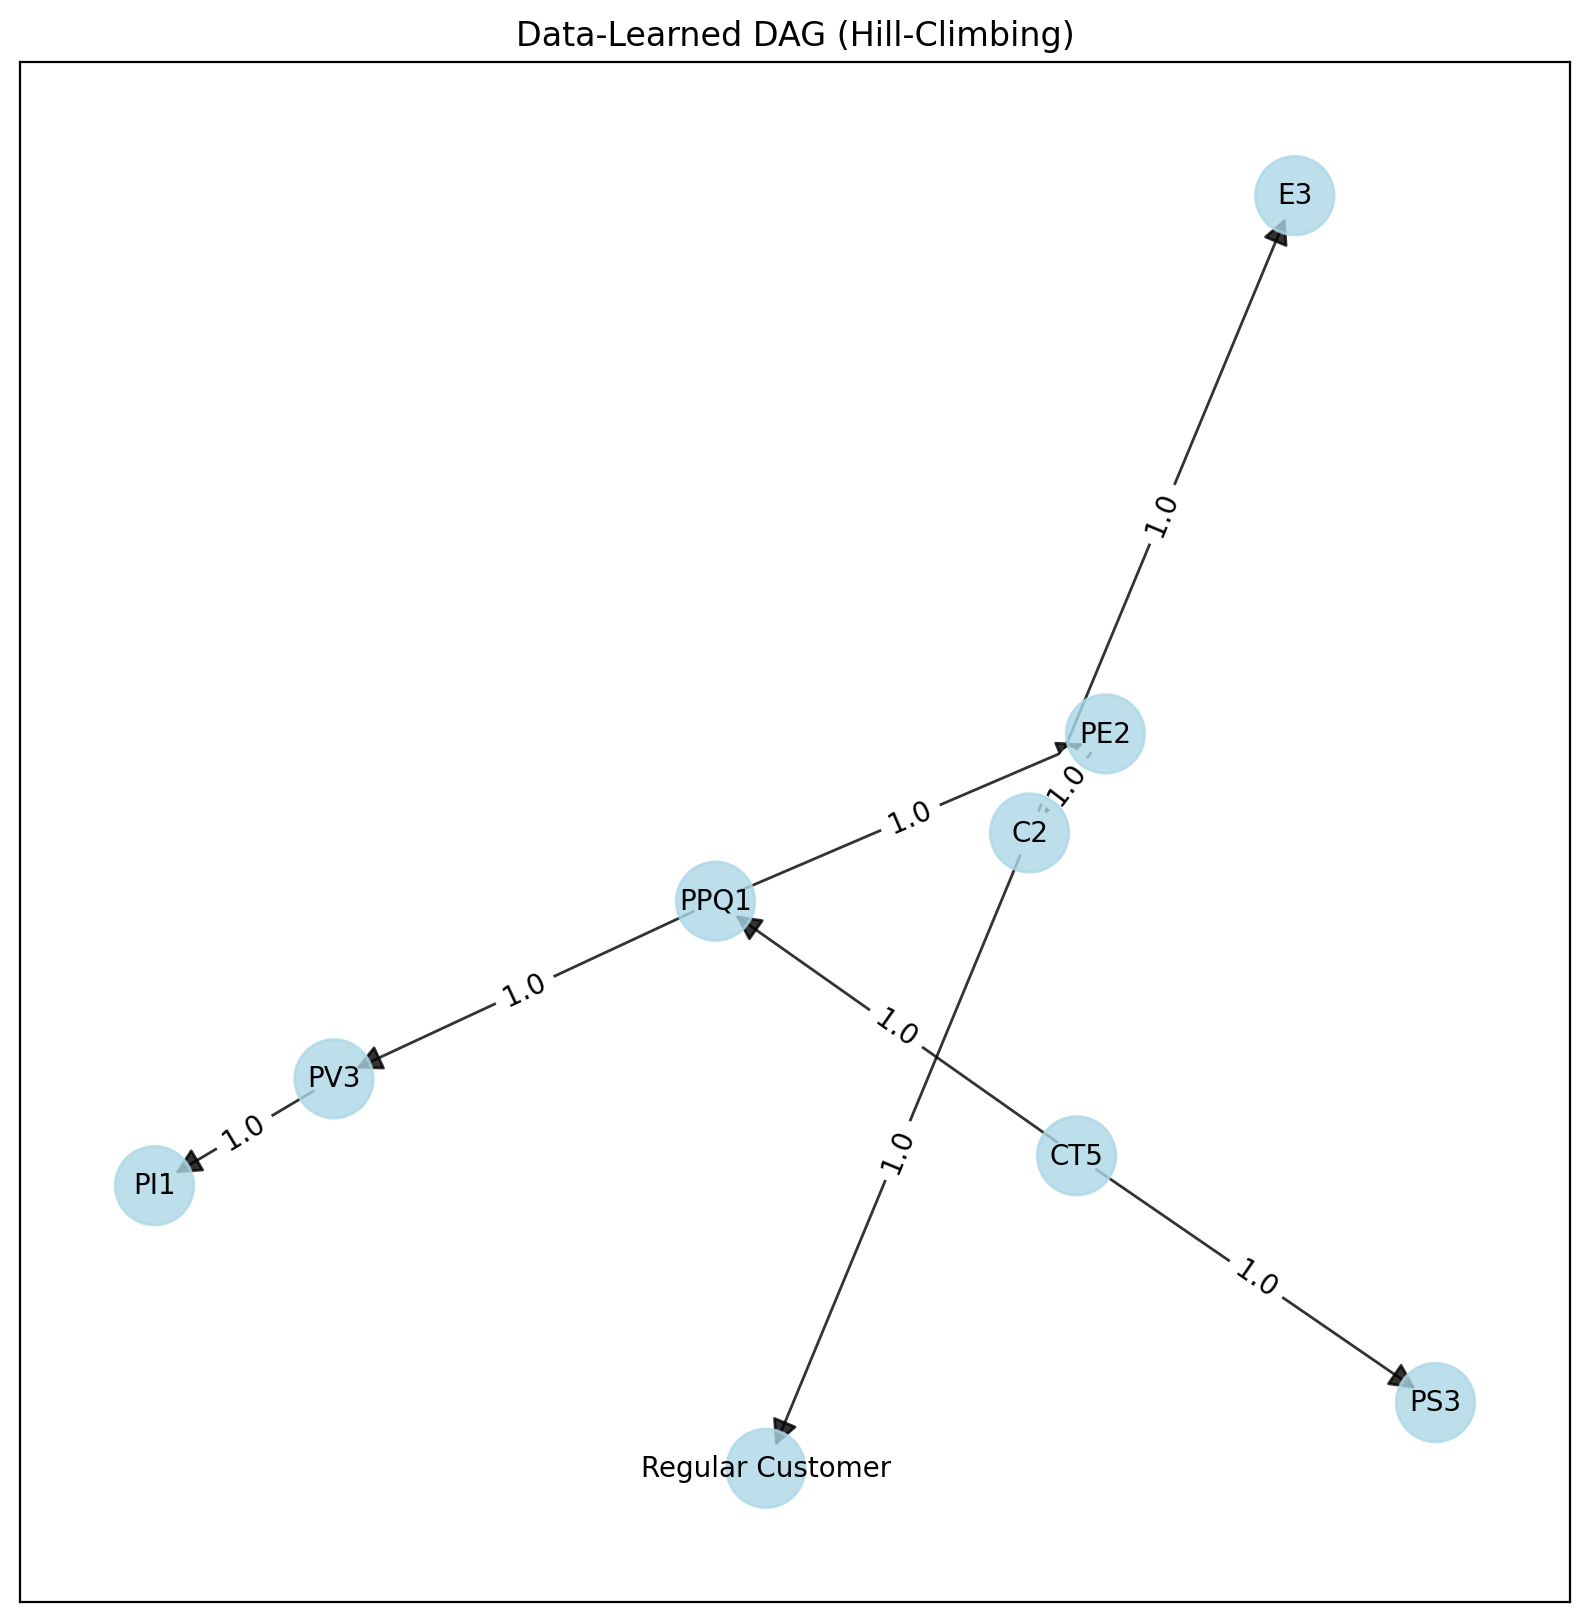

{'fig': <Figure size 2000x2000 with 1 Axes>,
 'ax': <Figure size 2000x2000 with 1 Axes>,
 'pos': {'Regular Customer': array([-0.13454595, -0.592185  ]),
  'E3': array([0.4940887, 1.       ]),
  'C2': array([0.17881431, 0.20273355]),
  'PS3': array([ 0.6612977 , -0.50984327]),
  'PE2': array([0.26904407, 0.32660108]),
  'PPQ1': array([-0.1944406 ,  0.11727225]),
  'CT5': array([ 0.23469111, -0.20121743]),
  'PV3': array([-0.64781195, -0.10482624]),
  'PI1': array([-0.86113739, -0.23853492])},
 'G': <networkx.classes.digraph.DiGraph at 0x78ef1f1f19d0>,
 'node_properties': {'Regular Customer': {'node_color': '#ADD8E6',
   'node_size': 800},
  'E3': {'node_color': '#ADD8E6', 'node_size': 800},
  'C2': {'node_color': '#ADD8E6', 'node_size': 800},
  'PS3': {'node_color': '#ADD8E6', 'node_size': 800},
  'PE2': {'node_color': '#ADD8E6', 'node_size': 800},
  'PPQ1': {'node_color': '#ADD8E6', 'node_size': 800},
  'CT5': {'node_color': '#ADD8E6', 'node_size': 800},
  'PV3': {'node_color': '#ADD8E

In [ ]:
#2.2
#select chosen 9 columns
selected_cols = [
    'Regular Customer', # Demographics
    'E3',               # Expectations
    'C2',               # Convenience
    'PS3',              # Product Selection
    'PE2',              # Physical Environment
    'PPQ1',             # Perceived Quality
    'CT5',              # Customer Trust
    'PV3',              # Perceived Value
    'PI1'               # Purchase Intention
]

df_selected = df_numeric[selected_cols].copy()

# Structure learning
dag_learned = bn.structure_learning.fit(df_selected, methodtype='hc', scoretype='bic')

#Plot
bn.plot(dag_learned, title="Data-Learned DAG (Hill-Climbing)")

##3. Comparison of DAGs

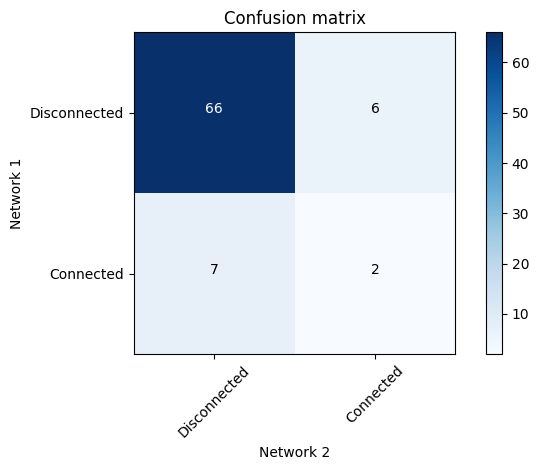

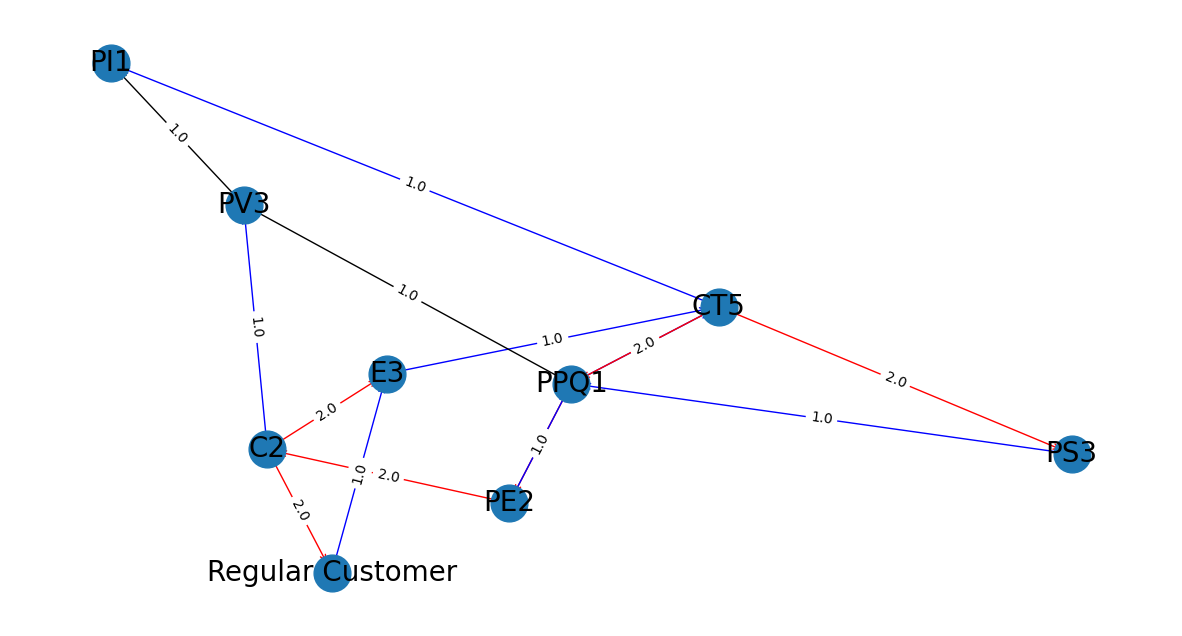

DAG Structural Comparison: (array([[66,  6],
       [ 7,  2]]), target            Regular Customer  E3  C2  PV3  PS3  PPQ1  PE2  CT5  PI1
source                                                                   
Regular Customer                 0  -1   0    0    0     0    0    0    0
E3                               0   0   0    0    0     0    0   -1    0
C2                               2   2   0   -1    0     0    0    0    0
PV3                              0   0   0    0    0     0    0    0    1
PS3                              0   0   0    0    0    -1    0    0    0
PPQ1                             0   0   0    1    0     0    2   -1    0
PE2                              0   0   2    0    0    -1    0    0    0
CT5                              0   0   0    0    2     2    0    0   -1
PI1                              0   0   0    0    0     0    0    0    0)


In [ ]:
#2.3
compare_results = bn.compare_networks(dag_expert, dag_learned)
print("DAG Structural Comparison:", compare_results)

1. What are the pros and cons of learning a DAG from data?


*   **Pros**: Learning a DAG from data helps in identifying hidden relationships by uncovering hidden interaction or links that might easily be missed by humans. It also helps in reducing human bias by bypassing established assumptions.
*   **Cons**: Sensitive to Data Noise and Sample size. The quality of the dataset has a significant impact on search algorithms like Hill-Climb. The technique can easily create incorrect or unstable network architectures if the sample size is small or contains measurement mistakes, missing values, or outliers.


2. In what situations would you opt to learn a DAG structure from data?


*   I would opt to learn DaG from data when historic past data is sufficient but limited expert knowledge when it comes to the relationships between variables. It is an efficient way for a researcher during explaratory analysis to identify the past unknown dependencies.
*   This is also useful when working with a large dataset that consist of multiple variables because the algorithm can efficiently search for relationships that are generally difficult to determine manually.




3. When would you prefer to create a DAG structure as an expert?

I would prefer to create DAG when the relationships between variables are already explained by known research and textbook theories. For instance, a customer's decision to buy may be influenced by perceived value and store convenience. Additionally, I would prefer a DAG structure when it will be used as a basis to support important business decisions.

4. Explain two risks associated with learning a DAG structure from data.



*   **Incorrect causal interpretation** - A huge risk learning a DAG from data is assuming that an association identified in the data represents a causal relationship. A data learning algortih can discover that two variables are statistically related but does not mean that one variable is caused the other. This may lead to inaccurate conclusion about the cause and effect.
*   **Poor quality data** - The learned DAg relies on the quality of the dataset. Inaccurate correlations may be learned by the algorithm due to missing values, measurement mistakes, short sample sizes, or biassed data. As a result, rather than reflecting the actual relationships between variables, the resulting DAG can represent issues with the dataset.



5. Explain two risks associated with creating a DAG structure as an expert.


*   **Subjective and Confirmation Bias**: Human experts are restricted by their personal theories, training and psychological biases. An expert will usually draw a graph that shows how they think a system should perform tasks, which blinds the model to hidden counter-intuitive patterns that go against traditional industry assumptions.
*   **Structural Omission and Missing Mediators**: IF a critical mediating variable is missed by the expert, the whole conditional probability distribution of the network becomes distorted. Leaving out important structural nodes causes the network to mix up real causes which leads to poor decisions and bad predictions.



##4. Create BN(Parameter Learning)

In [ ]:
#Parameter Learning
model_bn = bn.parameter_learning.fit(dag_expert,df_selected, methodtype='ml')

print("Parameter Learning Completed Successfully.")

[bnlearn] >Parameter learning> Computing parameters using [ml]
[bnlearn] >CPD of E3:
+------------------+---------------------+----------------------+
| Regular Customer | Regular Customer(1) | Regular Customer(2)  |
+------------------+---------------------+----------------------+
| E3(1)            | 0.08189655172413793 | 0.14285714285714285  |
+------------------+---------------------+----------------------+
| E3(2)            | 0.11206896551724138 | 0.22448979591836735  |
+------------------+---------------------+----------------------+
| E3(3)            | 0.3922413793103448  | 0.2857142857142857   |
+------------------+---------------------+----------------------+
| E3(4)            | 0.2974137931034483  | 0.2857142857142857   |
+------------------+---------------------+----------------------+
| E3(5)            | 0.11637931034482758 | 0.061224489795918366 |
+------------------+---------------------+----------------------+
[bnlearn] >CPD of PV3:
+--------+--------------------+---

##Question 3: Inference and Interpretation


##1. Inference Using the BN


In [ ]:
# Query 1: High Perceived Value (PV3=5) and High Trust (CT5=5)
q1 = bn.inference.fit(model_bn, variables=['PI1'], evidence={'PV3': 5, 'CT5': 5})

# Query 2: Low Perceived Value (PV3=1) and Low Trust (CT5=1)
q2 = bn.inference.fit(model_bn, variables=['PI1'], evidence={'PV3': 1, 'CT5': 1})

# Query 3: Regular Customer (Regular Customer=2) with High Convenience (C2=5)
q3 = bn.inference.fit(model_bn, variables=['PI1'], evidence={'Regular Customer': 2, 'C2': 5})

# Query 4: High Product Quality (PPQ1=5) with Hig Expectations (E3=5)
q4 = bn.inference.fit(model_bn, variables=['PI1'], evidence={'PPQ1': 5, 'E3': 5})

# Query 5: Low Physical Environment Score (PE2=1) but High Value (PV3=5)
q5 = bn.inference.fit(model_bn, variables=['PI1'], evidence={'PE2': 1, 'PV3': 5})

# Query 6: Irregular Customer (Regular Customer=1) with Low Trust (CT5=1)
q6 = bn.inference.fit(model_bn, variables=['PI1'], evidence={'Regular Customer': 1, 'CT5': 1})

[bnlearn] >Variable Elimination.
+----+-------+-----------+
|    |   PI1 |         p |
+====+=======+===========+
|  0 |     1 | 0         |
+----+-------+-----------+
|  1 |     2 | 0         |
+----+-------+-----------+
|  2 |     3 | 0.0444444 |
+----+-------+-----------+
|  3 |     4 | 0.177778  |
+----+-------+-----------+
|  4 |     5 | 0.777778  |
+----+-------+-----------+

Summary for variables: ['PI1']
Given evidence: PV3=5, CT5=5

PI1 outcomes:
- PI1: 1 (0.0%)
- PI1: 2 (0.0%)
- PI1: 3 (4.4%)
- PI1: 4 (17.8%)
- PI1: 5 (77.8%)
[bnlearn] >Variable Elimination.
+----+-------+-----+
|    |   PI1 |   p |
+====+=======+=====+
|  0 |     1 | 0.4 |
+----+-------+-----+
|  1 |     2 | 0.6 |
+----+-------+-----+
|  2 |     3 | 0   |
+----+-------+-----+
|  3 |     4 | 0   |
+----+-------+-----+
|  4 |     5 | 0   |
+----+-------+-----+

Summary for variables: ['PI1']
Given evidence: PV3=1, CT5=1

PI1 outcomes:
- PI1: 1 (40.0%)
- PI1: 2 (60.0%)
- PI1: 3 (0.0%)
- PI1: 4 (0.0%)
- PI1: 5 (

##2. Detailed Result Interpretation

Query 1: High Perceived Value(PV3 = 5) and High Customer Trust(CT5=5)


*   **Result Explanation**: When the the perceived value(PV3) and customer trust(CT5) are at level 5, this results in purchase intention reaching its peak. The model predicts a 77.8% probability for PI1 = 5 and 17.8% probability for PI1 = 4, and when combined results in 95.6% high purchase rate.   
*   **Business Implications**: High perceived value and and strong customer trust behave as the primary drivers that lead to customer conversion. Customer Trust minimises the perceived risk of purchasing while high value provides customers with a good reason to finish the purchase.

Query 2: Low Perceived Value(PV3=1) and Low Customer Trust(CT5=1)


*   **Result Explanation**:When perceived value and customer trust are at the lowest level(1), this results in the purchase intention reaching its lowest drop. The model predicts 60% for PI1 = 2 and 40% for PI1= 1, which results in a complete low purchase intent of 100%. The probability becomes 0% for high purchase intent
*   **Business Implication**: A lack of value in the business combined with with low trust results in failure to generate sales. Management must ensure that they fix the issues related to the product quality before they try to attract more customers.

Query 3: Regular Customer(Regular Customer=2) and High Store Convenience(C2=5)


*   **Result Explanation**: When maximum store convenience(C2=5) is experienced by customers shopping on a moderate basis(Regular Customer=2), this results in a positive purchase intent. The model predicts 45.3% probability for PI1 = 4 and a 22.9% probability for PI1 = 5, creating a total 68.1% positive purchase intent. The probability for low purchase intent remains low at 12.0%
*   **Business Implication**: Store Convenience acts as an important retention factor for regular customers. When the shopping process is easy, this helps to moderate buying intent from regular customers and prevents them from moving to rivals.

Query 4: High Product Quality(PPQ1=5) and High Expectations(E3=5)


*   **Result Explanation**: When perceived product quality(PPQ1=5) and customer expectations(E3=5) are at their highest level(5), the purchase intend remains high. The model shows 38.3% probability for PI1 = 5 and a 33.8% probability for PI1 = 4, which creates an overall 72.1% positive purchase intent.
*   **Business Implication**: Satisfying high customer expectations with the product quality eliminates any perceived risk in purchasing.

Query 5: Low Physical Environment(PE2=1) and High Perecived Value(PV3=5)


*   **Result Explanation**: When the physical store environment(PE2=1) obtains a low score and perceived value(PV3=5) is at the highest level, this results in a maintained strong purchase intent. The model forecast 55.3% probability for PI1=5 and a 17.6% probability for PI1=4 which sums to a 72.9% positive buying intent.
*   **Business Implication**: Perceived value shows to make up for poor store environment. Customers are able to overlook the bad store surroundings if they believe that the products results in a great value for their money. Strong product value holds its position as the driver of purchases even with low physical environment.

Query 6: Irregular Customer(Regular Customer=1)and Low Customer Trust(CT5=1)


*   **Result Explanation**: Customer who rarely shop(Regular Customer=1) and those who have low trust create a huge risk of loss and low purchase intent. The model predicts a 52.2% probability for PI1=4 and a 11.8% probability for PI1= 5, which results in a total 64.0% positive buying intent, while low purchase intent grows to 29.0%(13.0% for PI1=1 and 16.0% for PI1 = 2)
*   **Business Implication**: Irregular shoppers who rarely engage with the brand are bound to have low trust. Because they do not have excellent shopping experiences, their low trust results in failed sales.